<a href="https://colab.research.google.com/github/Prabuddhm98/Dav-lab/blob/main/Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


KeyboardInterrupt: 

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------              

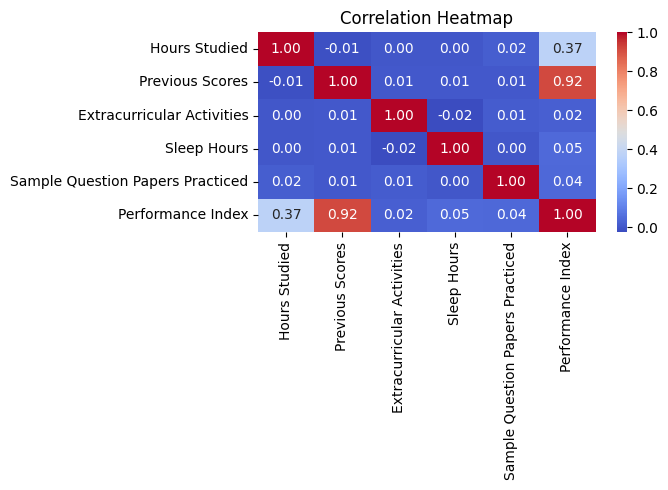

----- SIMPLE LINEAR REGRESSION -----
Intercept: 41.436634826535744
Slope (b1): 2.784300441170774
R2 Score: 0.13160425385996788
RMSE: 17.93919001285204


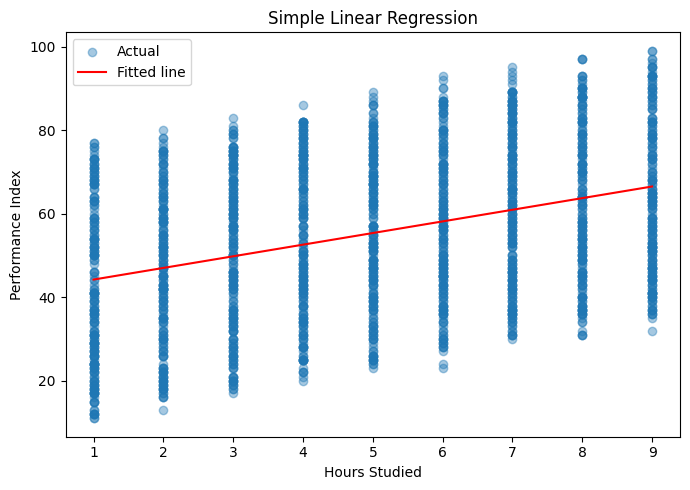

---------- MULTIPLE LINEAR REGRESSION ----------
Intercept: -33.92194621555638
Hours Studied                      : 2.8525
Previous Scores                    : 1.0170
Extracurricular Activities         : 0.6086
Sleep Hours                        : 0.4769
Sample Question Papers Practiced   : 0.1918
R2      : 0.9889832909573145
Adjusted: 0.9889556663107681
RMSE    : 2.0205515085050054


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
# 1. Load the dataset
df = pd.read_csv(r"C:\Users\user\Downloads\archive student\Student_Performance.csv")

# 2. Explore the data
print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# 3. Convert categorical data into numerical data
df['Extracurricular Activities'] = df['Extracurricular Activities'].map(
    {'Yes': 1, 'No': 0}
)

# 4. Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

# 5. Simple Linear Regression (1 Feature -> 1 Target)

# Independent variable
X_simple = df[['Hours Studied']]

# Dependent variable
y = df['Performance Index']

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

# 6. Make predictions
y_pred = simple_model.predict(X_test)

print("\nSimple Linear Regression Results:")
print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

print("\nActual Values:")
print(y_test.head().values)

print("\nPredicted Values:")
print(y_pred[:5])

# 7. Evaluate the model
print("\nMean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# 8. Plot Regression Line
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='blue', label='Actual Values')
plt.plot(X_test, y_pred, color='red', label='Regression Line')

plt.xlabel('Hours Studied')
plt.ylabel('Performance Index')
plt.title('Simple Linear Regression')
plt.legend()
plt.tight_layout()
plt.show()



In [14]:
X = df.drop(columns='Performance Index')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("---------- MULTIPLE LINEAR REGRESSION ----------")
print(f"Intercept: {multi_model.intercept_}")
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"{name:35s}: {coef:.4f}")

y_pred = multi_model.predict(X_test)

---------- MULTIPLE LINEAR REGRESSION ----------
Intercept: -33.92194621555638
Hours Studied                      : 2.8525
Previous Scores                    : 1.0170
Extracurricular Activities         : 0.6086
Sleep Hours                        : 0.4769
Sample Question Papers Practiced   : 0.1918



--- MULTIPLE LINEAR REGRESSION ---
Intercept: -33.92194621555638
 Hours Studied                       2.8525
 Previous Scores                     1.0170
 Extracurricular Activities          0.6086
 Sleep Hours                         0.4769
 Sample Question Papers Practiced    0.1918
R2           : 0.9889832909573145
Adjusted R2  : 0.9889556663107681
RMSE         : 2.0205515085050054

                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:10:20   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:             

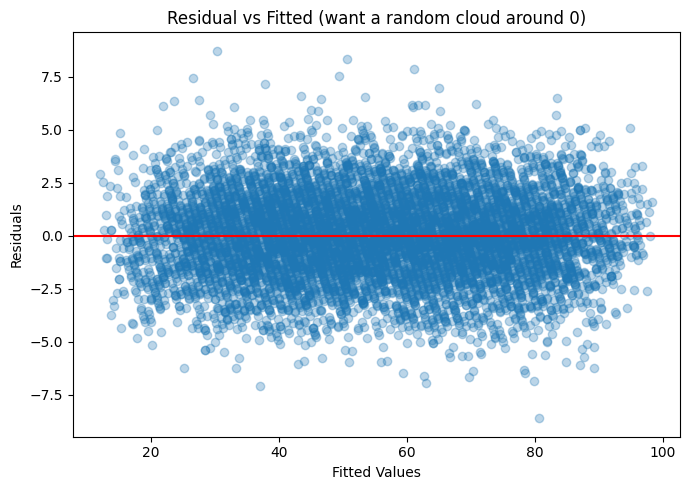

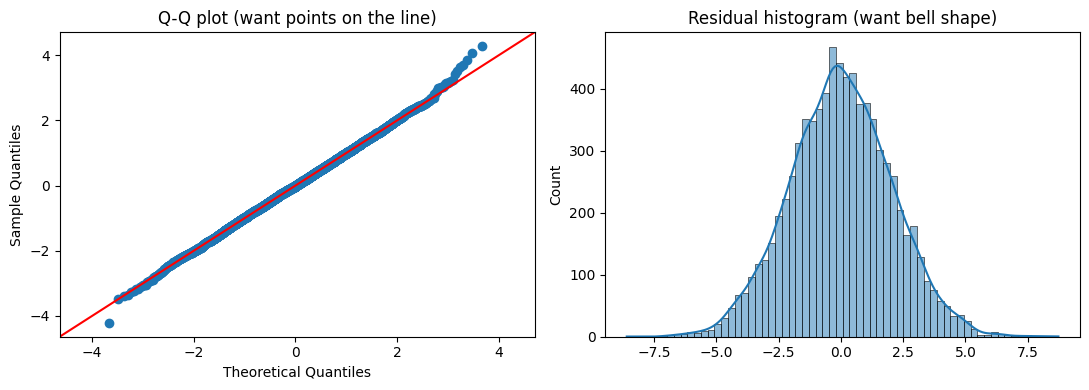

Breush-Pagan p-valve: 0.2396245087908097
Durbin-Watson : 2.0331060225040156

VIF:
                            feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


In [18]:
print("\n--- MULTIPLE LINEAR REGRESSION ---")
print("Intercept:", multi_model.intercept_)

for name, coef in zip(X.columns, multi_model.coef_):
    print(f" {name:35s} {coef:.4f}")

y_pred = multi_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2           :", r2)
print("Adjusted R2  :", adj_r2)
print("RMSE         :", rmse)

X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print("\n",ols.summary())
fitted = ols.fittedvalues
resid = ols.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color='red')
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residual vs Fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("residual_plot.png")
plt.show()

# 5b. Normality of residuals: Q-Q plot + histogram
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line='45', fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("h4_normality.png")
plt.show()

# 5c. Homoscedasticity test: Breusch-Pagan (p > 0.05 -> constant variance)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breush-Pagan p-valve:",bp_p)
print("Durbin-Watson :",durbin_watson(resid))

vif = pd.DataFrame({
    "feature": X_train_sm.columns,
    "VIF": [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
})

# Filter out the constant column if present
print("\nVIF:")
print(vif[vif["feature"] != "const"])






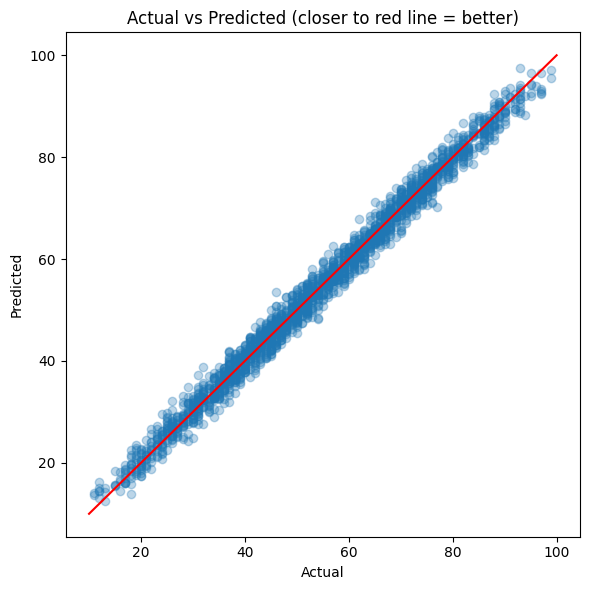

In [19]:
# 1. Set up the figure size
plt.figure(figsize=(6, 6))

# 2. Scatter plot of the actual test values vs. the predicted values
# 'alpha=0.3' makes the points semi-transparent to visualize density
plt.scatter(y_test, y_pred, alpha=0.3)

# 3. Plot a reference line representing perfect predictions (y = x)
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="red"
)

# 4. Set labels and title
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")

# 5. Automatically adjust subplot parameters to give specified padding
plt.tight_layout()

# 6. Save the plot as an image file
plt.savefig("actual_vs_pred.png")

# 7. Display the plot
plt.show()